In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [4]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [5]:
def getMcRcAndErrAndN(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['w'])
        nss = sum(df[df.bs==+1]['w'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n_array = []
    wtot_array = []
    for i in range(0, len(w_array)):
        n_array.append( df[df.w == w_array[i]].shape[0] )
        wtot_array.append( sum(df[df.w == w_array[i]]['w']) )
    n = 0
    for i in range(0, len(w_array)):
        if (wtot_array[i] != 0):
            n += wtot_array[i]*n_array[i]/sum(wtot_array)
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [6]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [7]:
observables1 = ['pt','m','q2','rg','zg','mg','b']
file = uproot.open('/vast/palmer/home.grace/ys668/output/run12/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df = applyCut(df, 'pts>15 and bs!=-9 and bs!=0')

In [8]:
df.shape[0]

659347

In [9]:
df_15 = applyCut(df, '15 < pts < 20')
df_20 = applyCut(df, '20 < pts < 25')
df_25 = applyCut(df, '25 < pts < 30')
df_30 = applyCut(df, '30 < pts < 40')

In [10]:
print(getRcAndErrAndN(df_15, 'bs'))
print(getRcAndErrAndN(df_20, 'bs'))
print(getRcAndErrAndN(df_25, 'bs'))
print(getRcAndErrAndN(df_30, 'bs'))

(-0.3087933449476, 0.0013247772219597514, 515458)
(-0.3049137767841851, 0.002859432635262245, 110933)
(-0.30877555891479036, 0.005998971104851678, 25138)
(-0.2980493793479744, 0.011148521567582732, 7331)


In [11]:
data_rc_15, data_rc_err_15, n_15 = getRcAndErrAndN(df_15, 'bs')
data_rc_20, data_rc_err_20, n_20 = getRcAndErrAndN(df_20, 'bs')
data_rc_25, data_rc_err_25, n_25 = getRcAndErrAndN(df_25, 'bs')
data_rc_30, data_rc_err_30, n_30 = getRcAndErrAndN(df_30, 'bs')

In [12]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [13]:
y_rec_15,yerr_rec_15,x = calc_hist(df_15[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
y_rec_20,yerr_rec_20,x = calc_hist(df_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
y_rec_25,yerr_rec_25,x = calc_hist(df_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
y_rec_30,yerr_rec_30,x = calc_hist(df_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))

In [14]:
data_array = np.array([y_rec_15, y_rec_20,y_rec_25,y_rec_30])

In [15]:
data_err_array = np.array([yerr_rec_15, yerr_rec_20,yerr_rec_25,yerr_rec_30])

In [16]:
print(data_array)
print(data_err_array)

[[337314. 178144.]
 [ 72379.  38554.]
 [ 16450.   8688.]
 [  4758.   2573.]]
[[580.78739656 422.07108406]
 [269.03345517 196.35172523]
 [128.25755338  93.20944158]
 [ 68.97825744  50.72474741]]


In [17]:
fake_rate_array = np.array([0.29240932, 0.27973313, 0.23650474, 0.22628239])

In [18]:
fake_dist_array = np.array([[0.62625969, 0.37374031], [0.60864417, 0.39135583], [0.59417459,0.40582541], [0.60064745, 0.39935255]])

In [19]:
fake_err_array = np.array([[0.0222481, 0.01483346], [0.02912147, 0.02331168], [0.02493272, 0.02715528], [0.05058158, 0.04618194]])

In [20]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [21]:
y1_array = []
y1err_array = []
rc1_array = []
rc1err_array = []
for i in range(0,4):
    print(i)
    print(data_array[i])
    #print(getRc(data_array[i]))
    y1, y1err = getMatchedCountAndErr(data_array[i], fake_rate_array[i], fake_dist_array[i])
    y1_array.append(y1)
    y1err_array.append(y1err)
    print(y1)
    print(y1err)
    nos = y1[0]
    nss = y1[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1err_array.append( 2*np.sqrt(p*(1-p)/n) )

0
[337314. 178144.]
[242921.1815305  121812.09520094]
[492.87034962 349.01589534]
1
[72379. 38554.]
[53491.77608283 26409.58860688]
[231.28289189 162.51027231]
2
[16450.  8688.]
[12917.47986218  6275.2639837 ]
[113.65509167  79.21656382]
3
[4758. 2573.]
[3761.60023995 1910.52355896]
[61.331886   43.70953625]


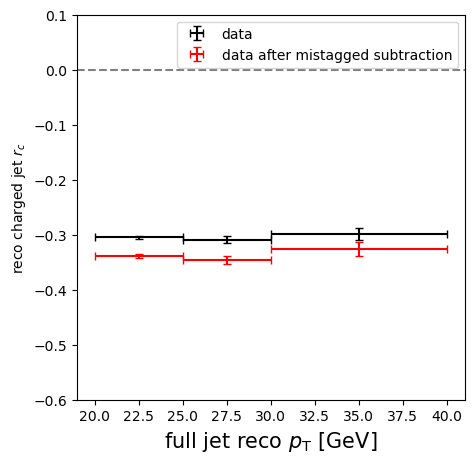

In [24]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], [data_rc_20, data_rc_25, data_rc_30], xerr=[2.5, 2.5, 5], yerr=[data_rc_err_20, data_rc_err_25, data_rc_err_30], capsize=3, ls='none', label='data', color='k')
plt.errorbar([22.5, 27.5, 35], rc1_array[1:], xerr=[2.5, 2.5, 5], yerr=rc1err_array[1:], capsize=3, ls='none', label='data after mistagged subtraction', color='r')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(fontsize=10)

In [25]:
rc1_array

[-0.3320483598723748,
 -0.3389452430645336,
 -0.3460795356734463,
 -0.3263463116487207]

In [26]:
rc1err_array

[0.0015618697447511644,
 0.003328304308617994,
 0.006772192457235017,
 0.012550873791080731]

In [27]:
ob = 'b'
range_low = -1.
range_high = 1.2
bins = 5

Scaling new embedding

In [28]:
y1_pythia_array = np.array([[0.69372956, 0.30627044], [0.69209685, 0.30790315], [0.68951847, 0.31048153], [0.6959566, 0.3040434]])
y1err_pythia_array = np.array([[0.00469157, 0.00285177], [0.00525327, 0.00329527], [0.00568226, 0.00444353], [0.00564118, 0.00365521]])

In [29]:
y1_array[0]

array([242921.1815305 , 121812.09520094])

([], [])

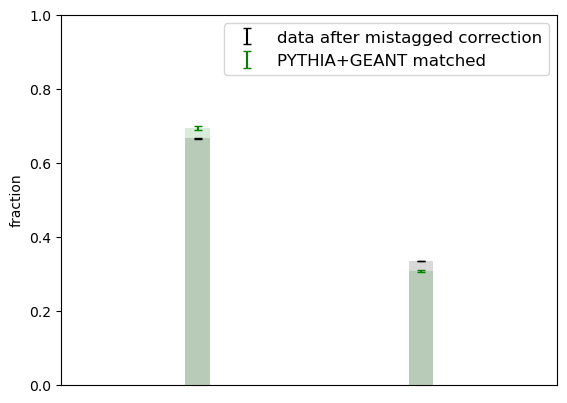

In [36]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=y1_array[0]/sum(y1_array[0]), color='k', alpha=0.15)
plt.hist(x, weights=y1_pythia_array[0]/sum(y1_pythia_array[0]), ls='none', color='g', alpha=0.15)
plt.errorbar(x+np.array([0.05,-0.05]), y1_array[0]/sum(y1_array[0]), yerr=y1err_array[0]/sum(y1_array[0]), capsize=3, color='k', label='data after mistagged correction', ls='none')
plt.errorbar(x+np.array([0.05,-0.05]), y1_pythia_array[0]/sum(y1_pythia_array[0]), yerr=y1err_pythia_array[0]/sum(y1_pythia_array[0]), capsize=3, color='g', label='PYTHIA+GEANT matched', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

In [33]:
(y1_array[0]/sum(y1_array[0])) / (y1_pythia_array[0]/sum(y1_pythia_array[0]))

array([0.96006314, 1.09046051])

([], [])

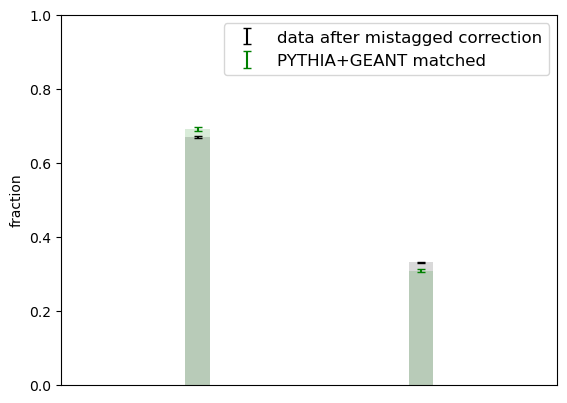

In [94]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=y1_array[1]/sum(y1_array[1]), color='k', alpha=0.15)
plt.hist(x, weights=y1_pythia_array[1]/sum(y1_pythia_array[1]), ls='none', color='g', alpha=0.15)
plt.errorbar(x+np.array([0.05,-0.05]), y1_array[1]/sum(y1_array[1]), yerr=y1err_array[1]/sum(y1_array[1]), capsize=3, color='k', label='data after mistagged correction', ls='none')
plt.errorbar(x+np.array([0.05,-0.05]), y1_pythia_array[1]/sum(y1_pythia_array[1]), yerr=y1err_pythia_array[1]/sum(y1_pythia_array[1]), capsize=3, color='g', label='PYTHIA+GEANT matched', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

In [95]:
(y1_array[1]/sum(y1_array[1])) / (y1_pythia_array[1]/sum(y1_pythia_array[1]))

array([0.9673106 , 1.07347839])

([], [])

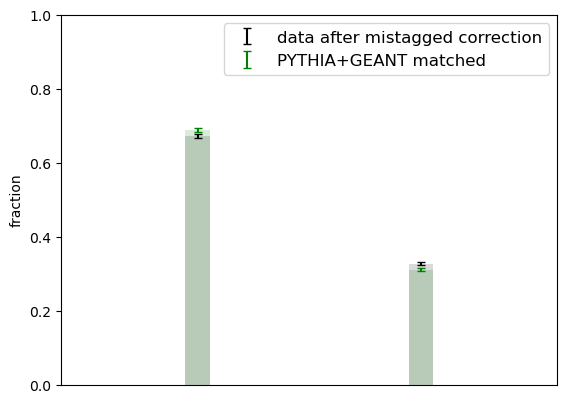

In [96]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=y1_array[2]/sum(y1_array[2]), color='k', alpha=0.15)
plt.hist(x, weights=y1_pythia_array[2]/sum(y1_pythia_array[2]), ls='none', color='g', alpha=0.15)
plt.errorbar(x+np.array([0.05,-0.05]), y1_array[2]/sum(y1_array[2]), yerr=y1err_array[2]/sum(y1_array[2]), capsize=3, color='k', label='data after mistagged correction', ls='none')
plt.errorbar(x+np.array([0.05,-0.05]), y1_pythia_array[2]/sum(y1_pythia_array[2]), yerr=y1err_pythia_array[2]/sum(y1_pythia_array[2]), capsize=3, color='g', label='PYTHIA+GEANT matched', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

In [97]:
(y1_array[2]/sum(y1_array[2])) / (y1_pythia_array[2]/sum(y1_pythia_array[2]))

array([0.97610114, 1.05307466])

Scale the old embedding

In [37]:
y1_pythia_array = np.array([[0.71259924, 0.28740076], [0.70636007, 0.29363993], [0.69049691, 0.30950309], [0.70483795, 0.29516205]])
y1err_pythia_array = np.array([[0.01618466, 0.00916108], [0.0189809, 0.01136867], [0.01834966, 0.0118916], [0.02715301, 0.01526591]])

([], [])

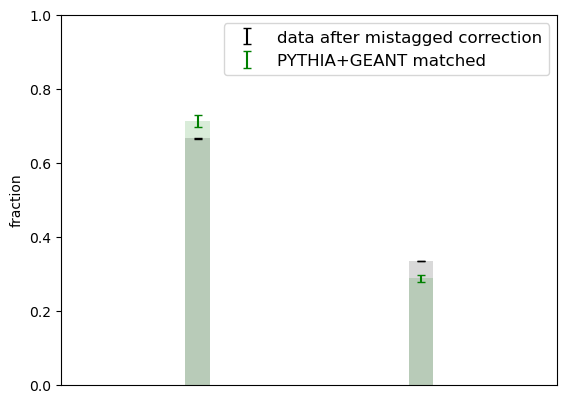

In [38]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=y1_array[0]/sum(y1_array[0]), color='k', alpha=0.15)
plt.hist(x, weights=y1_pythia_array[0]/sum(y1_pythia_array[0]), ls='none', color='g', alpha=0.15)
plt.errorbar(x+np.array([0.05,-0.05]), y1_array[0]/sum(y1_array[0]), yerr=y1err_array[0]/sum(y1_array[0]), capsize=3, color='k', label='data after mistagged correction', ls='none')
plt.errorbar(x+np.array([0.05,-0.05]), y1_pythia_array[0]/sum(y1_pythia_array[0]), yerr=y1err_pythia_array[0]/sum(y1_pythia_array[0]), capsize=3, color='g', label='PYTHIA+GEANT matched', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

In [39]:
(y1_array[0]/sum(y1_array[0])) / (y1_pythia_array[0]/sum(y1_pythia_array[0]))

array([0.9346406 , 1.16205615])

([], [])

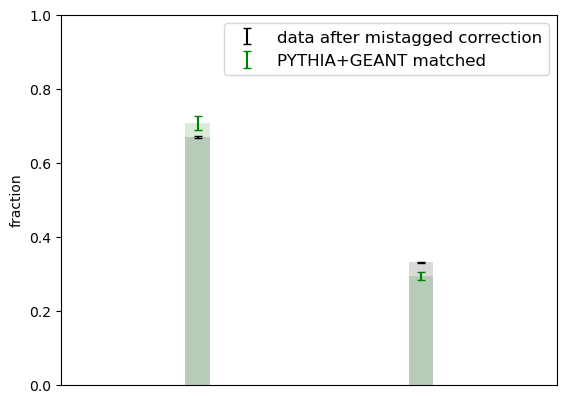

In [40]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=y1_array[1]/sum(y1_array[1]), color='k', alpha=0.15)
plt.hist(x, weights=y1_pythia_array[1]/sum(y1_pythia_array[1]), ls='none', color='g', alpha=0.15)
plt.errorbar(x+np.array([0.05,-0.05]), y1_array[1]/sum(y1_array[1]), yerr=y1err_array[1]/sum(y1_array[1]), capsize=3, color='k', label='data after mistagged correction', ls='none')
plt.errorbar(x+np.array([0.05,-0.05]), y1_pythia_array[1]/sum(y1_pythia_array[1]), yerr=y1err_pythia_array[1]/sum(y1_pythia_array[1]), capsize=3, color='g', label='PYTHIA+GEANT matched', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

In [41]:
(y1_array[1]/sum(y1_array[1])) / (y1_pythia_array[1]/sum(y1_pythia_array[1]))

array([0.94777812, 1.12562136])

([], [])

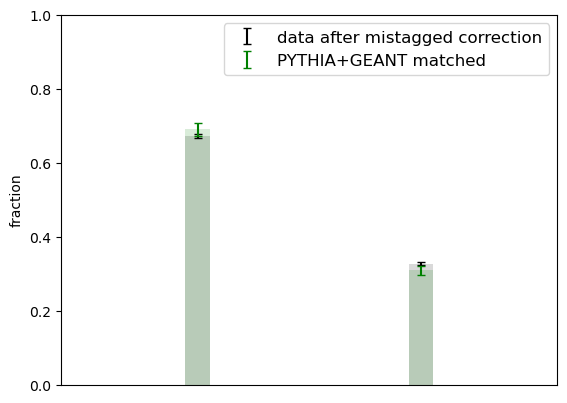

In [42]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=y1_array[2]/sum(y1_array[2]), color='k', alpha=0.15)
plt.hist(x, weights=y1_pythia_array[2]/sum(y1_pythia_array[2]), ls='none', color='g', alpha=0.15)
plt.errorbar(x+np.array([0.05,-0.05]), y1_array[2]/sum(y1_array[2]), yerr=y1err_array[2]/sum(y1_array[2]), capsize=3, color='k', label='data after mistagged correction', ls='none')
plt.errorbar(x+np.array([0.05,-0.05]), y1_pythia_array[2]/sum(y1_pythia_array[2]), yerr=y1err_pythia_array[2]/sum(y1_pythia_array[2]), capsize=3, color='g', label='PYTHIA+GEANT matched', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

In [43]:
(y1_array[2]/sum(y1_array[2])) / (y1_pythia_array[2]/sum(y1_pythia_array[2]))

array([0.974718  , 1.05640377])

([], [])

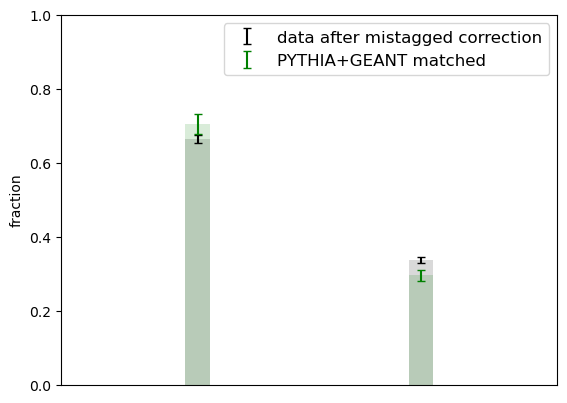

In [44]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=y1_array[3]/sum(y1_array[3]), color='k', alpha=0.15)
plt.hist(x, weights=y1_pythia_array[3]/sum(y1_pythia_array[3]), ls='none', color='g', alpha=0.15)
plt.errorbar(x+np.array([0.05,-0.05]), y1_array[3]/sum(y1_array[3]), yerr=y1err_array[3]/sum(y1_array[3]), capsize=3, color='k', label='data after mistagged correction', ls='none')
plt.errorbar(x+np.array([0.05,-0.05]), y1_pythia_array[3]/sum(y1_pythia_array[3]), yerr=y1err_pythia_array[3]/sum(y1_pythia_array[3]), capsize=3, color='g', label='PYTHIA+GEANT matched', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

In [45]:
(y1_array[3]/sum(y1_array[3])) / (y1_pythia_array[3]/sum(y1_pythia_array[3]))

array([0.94088741, 1.14115905])